# 🚀 Week 10 — Mini Project: End-to-End Pipeline & Presentation

ในบทเรียนสุดท้ายของหลักสูตร เราจะรวมองค์ความรู้ทั้งหมดตั้งแต่ Week 01–09 มาสร้างเป็น **Data Analysis Pipeline ที่ทำงานซ้ำได้อัตโนมัติ (Reproducible Pipeline)** พร้อมส่งมอบรายงานและกราฟนำเสนอผลงานระดับมืออาชีพ


## 📌 องค์ประกอบของ Data Pipeline คุณภาพสูง

1. **ฟังก์ชันโหลดและทำความสะอาด (`load_and_clean_data`):** จัดการ missing values และชนิดข้อมูล
2. **ฟังก์ชันวิเคราะห์ข้อมูล (`perform_analysis`):** คำนวณค่าสถิติเชิงลึกแยกตามหมวดหมู่
3. **ฟังก์ชันสร้างกราฟนำเสนอ (`create_presentation_chart`):** สร้างกราฟมาตรฐานพร้อมบันทึกไฟล์ภาพ
4. **ฟังก์ชันรายงานข้อสรุป 3 มิติ (`generate_executive_summary`):** สรุปผลคำตอบ หลักฐาน และข้อจำกัด
5. **Main Execution Block:** รันคำสั่งทั้งหมดจากบนลงล่างได้อย่างสมบูรณ์ (`Restart Kernel -> Run All`)


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. Pipeline Function: โหลดและทำความสะอาดข้อมูล
# ==============================================================================
def load_and_clean_data(file_path):
    """โหลดไฟล์ CSV, จัดการ missing value และแปลงชนิดข้อมูลให้พร้อมวิเคราะห์"""
    data = pd.read_csv(file_path)
    data["value_millions"] = pd.to_numeric(data["value_millions"], errors="coerce")
    data["age"] = pd.to_numeric(data["age"], errors="coerce")
    
    # เติมค่าว่าง median ให้กับ height_cm และ drop แถวที่ไม่มีราคา
    clean_data = data.dropna(subset=["value_millions", "overall"]).copy()
    if "height_cm" in clean_data.columns:
        clean_data["height_cm"] = clean_data["height_cm"].fillna(clean_data["height_cm"].median())
        
    print(f"✓ โหลดและ Clean ข้อมูลสำเร็จ: {len(clean_data)} แถว")
    return clean_data

In [2]:
# ==============================================================================
# 2. Pipeline Function: วิเคราะห์และจัดกลุ่มข้อมูล
# ==============================================================================
def perform_analysis(df, group_col="position", target_col="value_millions"):
    """จัดกลุ่มข้อมูลและคำนวณค่าสถิติหลายมิติ"""
    result = (
        df.groupby(group_col)[target_col]
        .agg(count="count", mean="mean", median="median", max="max")
        .sort_values(by="mean", ascending=False)
        .round(1)
        .reset_index()
    )
    print(f"✓ วิเคราะห์ข้อมูล {target_col} แยกตาม {group_col} สำเร็จ")
    return result

In [3]:
# ==============================================================================
# 3. Pipeline Function: สร้างและบันทึกกราฟนำเสนอ
# ==============================================================================
def create_presentation_chart(stats_df, group_col="position", target_col="mean", save_path="final_project_chart.png"):
    """สร้างกราฟแท่งที่ปรับแต่งสวยงาม พร้อมบันทึกภาพ"""
    plt.figure(figsize=(9, 4.8))
    bars = plt.bar(stats_df[group_col], stats_df[target_col], color="#1d3557", edgecolor="black", alpha=0.9)
    
    # แสดงตัวเลขบนแท่งกราฟ
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f"{yval:.1f}M", ha="center", va="bottom", fontsize=9, fontweight="bold")
        
    plt.title("Average Market Value by Position (Top Footballers)", fontsize=14, fontweight="bold", pad=15)
    plt.xlabel("Position", fontsize=11, fontweight="bold")
    plt.ylabel("Average Value (Million €)", fontsize=11, fontweight="bold")
    plt.ylim(0, max(stats_df[target_col]) * 1.15)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"✓ สร้างและบันทึกกราฟลงไฟล์ {save_path} เรียบร้อยแล้ว")

In [4]:
# ==============================================================================
# 4. Pipeline Function: รายงานสรุปผล 3 มิติสำหรับผู้บริหาร
# ==============================================================================
def generate_executive_summary(stats_df, group_col="position"):
    """สร้างบทสรุป 3 มิติ (คำตอบ, หลักฐาน, ข้อจำกัด)"""
    top_pos = stats_df.iloc[0]
    total_players = stats_df["count"].sum()
    
    summary = f"""
================================================================================
📋 รายงานสรุปผล Capstone Mini Project (Executive Summary)
================================================================================
1. [สิ่งที่เห็น / คำตอบ]:
   ตำแหน่งแนวรุก '{top_pos[group_col]}' ครองมูลค่าประเมินเฉลี่ยสูงสุดในตลาดนักเตะ

2. [หลักฐานเชิงประจักษ์]:
   - ค่าตัวเฉลี่ยอยู่ที่ {top_pos['mean']} ล้านยูโร (มัธยฐาน {top_pos['median']} ล้านยูโร)
   - ค่าตัวสูงสุดในตำแหน่งนี้แตะระดับ {top_pos['max']} ล้านยูโร

3. [ข้อจำกัดและข้อเสนอแนะ]:
   - ชุดข้อมูลมีขนาดกลุ่มตัวอย่างรวม {total_players} คนจากลีกชั้นนำเท่านั้น
   - การนำโมเดลไปใช้กับลีกระดับรองควรเพิ่มข้อมูลนักเตะท้องถิ่นเพื่อปรับสเกลความแม่นยำ
================================================================================
"""
    print(summary)

---
## 5️⃣ Main Pipeline Execution (ทดสอบรันจากบนลงล่าง)


🚀 กำลังเริ่มต้นรัน Data Pipeline...
✓ โหลดและ Clean ข้อมูลสำเร็จ: 45 แถว
✓ วิเคราะห์ข้อมูล value_millions แยกตาม position สำเร็จ


,position,count,mean,median,max
0,CM,5,106.0,100.0,150.0
1,ST,8,98.8,100.0,180.0
2,CAM,6,97.5,100.0,130.0
3,LW,6,95.0,95.0,150.0
4,CDM,3,78.3,100.0,110.0
5,RW,4,72.5,57.5,130.0
6,RB,2,67.5,67.5,70.0
7,LB,2,65.0,65.0,65.0
8,CB,6,56.7,57.5,80.0
9,GK,3,46.7,45.0,65.0


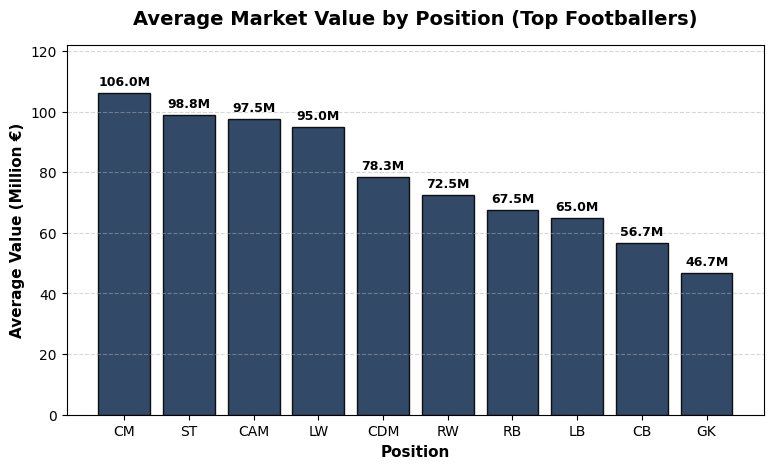

✓ สร้างและบันทึกกราฟลงไฟล์ final_project_chart.png เรียบร้อยแล้ว

📋 รายงานสรุปผล Capstone Mini Project (Executive Summary)
1. [สิ่งที่เห็น / คำตอบ]:
   ตำแหน่งแนวรุก 'CM' ครองมูลค่าประเมินเฉลี่ยสูงสุดในตลาดนักเตะ

2. [หลักฐานเชิงประจักษ์]:
   - ค่าตัวเฉลี่ยอยู่ที่ 106.0 ล้านยูโร (มัธยฐาน 100.0 ล้านยูโร)
   - ค่าตัวสูงสุดในตำแหน่งนี้แตะระดับ 150.0 ล้านยูโร

3. [ข้อจำกัดและข้อเสนอแนะ]:
   - ชุดข้อมูลมีขนาดกลุ่มตัวอย่างรวม 45 คนจากลีกชั้นนำเท่านั้น
   - การนำโมเดลไปใช้กับลีกระดับรองควรเพิ่มข้อมูลนักเตะท้องถิ่นเพื่อปรับสเกลความแม่นยำ

🎉 ยินดีด้วย! คุณผ่านการทำ Data Pipeline และ Capstone Mini Project เรียบร้อยแล้ว


In [5]:
# ==============================================================================
# 5. Main Execution: รันกระบวนการทั้งหมดตั้งแต่ต้นจนจบ
# ==============================================================================
print("🚀 กำลังเริ่มต้นรัน Data Pipeline...")

# Step 1: Ingestion & Cleaning
clean_data = load_and_clean_data("../data/footballers.csv")

# Step 2: Analysis
pos_stats = perform_analysis(clean_data, group_col="position", target_col="value_millions")
display(pos_stats)

# Step 3: Visualization
create_presentation_chart(pos_stats, group_col="position", target_col="mean", save_path="final_project_chart.png")

# Step 4: Storytelling & Summary
generate_executive_summary(pos_stats, group_col="position")

print("🎉 ยินดีด้วย! คุณผ่านการทำ Data Pipeline และ Capstone Mini Project เรียบร้อยแล้ว")